# Coordenação Descentralizada: Handoffs e Swarm

Sem supervisor, quem decide o próximo passo é o agente que está com a conversa. O **handoff** transfere o controle entre agentes, e o **swarm** é a arquitetura em que todo agente pode transferir e cada turno começa pelo **agente ativo**. O exemplo principal é o suporte de um provedor de internet.

In [1]:
# No Google Colab, descomente e rode uma vez.

# !pip install -q langchain langchain-openai langgraph langgraph-swarm

# import os
# from google.colab import userdata

# os.environ["OPENAI_API_KEY"] = userdata.get("OPENAI_API_KEY")

In [2]:
import io
import json
from contextlib import redirect_stdout
from urllib.parse import quote
from urllib.request import Request, urlopen

import pandas as pd
from IPython.display import Image
from langchain.agents import create_agent
from langchain.chat_models import init_chat_model
from langchain.messages import ToolMessage
from langchain.tools import ToolRuntime, tool
from langgraph.checkpoint.memory import InMemorySaver
from langgraph.graph import START, MessagesState, StateGraph
from langgraph.types import Command
from langgraph_swarm import create_handoff_tool, create_swarm

O `parallel_tool_calls` fica desligado: uma chamada feita junto com um handoff ficaria sem resposta, e o provedor recusaria a conversa.

In [3]:
model = init_chat_model(
    "openai:gpt-4.1-mini",
    temperature=0.0,
    model_kwargs={"parallel_tool_calls": False},
)

In [4]:
def user_message(text):
    """Monta a entrada do agente com uma mensagem do usuário."""
    return {"messages": [{"role": "user", "content": text}]}

## Handoff

No suporte de um provedor de internet, a triagem transfere o cliente para o técnico, que consulta as quedas da conexão, ou para o financeiro, que dá desconto na fatura.

In [5]:
@tool
def check_connection() -> str:
    """Consulta o registro de quedas da conexão do cliente."""
    return "5 dias sem conexão neste mês, por falha na rede do bairro, já corrigida"


@tool
def apply_credit(days: int) -> str:
    """Aplica na próxima fatura um crédito de R$ 3,00 por dia sem conexão."""
    return f"crédito de R$ {3 * days},00 aplicado na próxima fatura"

In [6]:
TRIAGE_PROMPT = """# Papel
Você é o atendente de triagem de um provedor de internet.

# Regras
Sua única ação é transferir o cliente para quem resolve o pedido:
- problemas de conexão vão para technician;
- faturas, cobranças e descontos vão para billing.
Um pedido de desconto por queda de conexão passa primeiro por technician.
Você nunca responde ao cliente."""

In [7]:
TECHNICIAN_PROMPT = """# Papel
Você é o técnico de um provedor de internet.

# Regras
Comece todo atendimento consultando as quedas da conexão com check_connection.
Responda ao cliente em até duas frases, com o que a consulta mostrou."""

BILLING_PROMPT = """# Papel
Você é o financeiro de um provedor de internet.

# Regras
Dê desconto por queda de conexão com apply_credit, usando os dias que o técnico consultou.
Responda ao cliente em até duas frases, com o valor do crédito."""

Um handoff é uma ferramenta que devolve um `Command`: o `goto` aponta o próximo agente, e `graph=Command.PARENT` faz o desvio no grafo dos agentes. Ela leva só o par da chamada: o pedido de transferência e a `ToolMessage` que responde a ele.

In [8]:
@tool
def transfer_to_technician(runtime: ToolRuntime) -> Command:
    """Transfere o cliente para o técnico."""
    transfer_message = ToolMessage(content="Transferido para technician.", tool_call_id=runtime.tool_call_id)
    return Command(
        goto="technician",
        update={"messages": [runtime.state["messages"][-1], transfer_message]},
        graph=Command.PARENT,
    )

In [9]:
@tool
def transfer_to_billing(runtime: ToolRuntime) -> Command:
    """Transfere o cliente para o financeiro."""
    transfer_message = ToolMessage(content="Transferido para billing.", tool_call_id=runtime.tool_call_id)
    return Command(
        goto="billing",
        update={"messages": [runtime.state["messages"][-1], transfer_message]},
        graph=Command.PARENT,
    )

In [10]:
triage_agent = create_agent(
    model,
    tools=[transfer_to_technician, transfer_to_billing],
    system_prompt=TRIAGE_PROMPT,
    name="triage",
)
technician_agent = create_agent(
    model,
    tools=[check_connection],
    system_prompt=TECHNICIAN_PROMPT,
    name="technician",
)
billing_agent = create_agent(
    model,
    tools=[apply_credit],
    system_prompt=BILLING_PROMPT,
    name="billing",
)

O grafo começa pela triagem, e `destinations` desenha os destinos dos seus handoffs. Os outros não têm aresta de saída, e a execução termina quando um deles responde.

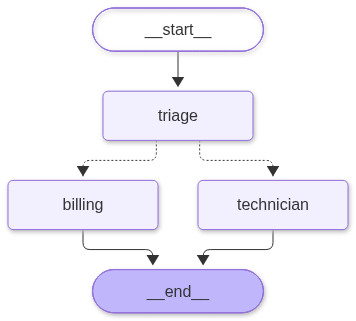

In [11]:
builder = StateGraph(MessagesState)
builder.add_node(triage_agent, destinations=("technician", "billing"))
builder.add_node(technician_agent)
builder.add_node(billing_agent)
builder.add_edge(START, "triage")

graph = builder.compile()
Image(graph.get_graph().draw_mermaid_png())

In [12]:
%%time
handoff_result = graph.invoke(user_message("Minha internet passou dias fora do ar. O que aconteceu?"))

CPU times: user 71.3 ms, sys: 12.9 ms, total: 84.1 ms
Wall time: 2.25 s


A função `steps` resume a conversa, com uma linha por mensagem e os tokens de entrada de cada chamada.

In [13]:
pd.set_option("display.max_colwidth", 100)


def steps(messages):
    """Resume cada mensagem em uma linha: quem escreveu, o que fez e os tokens de entrada."""
    rows = []
    for message in messages:
        calls = getattr(message, "tool_calls", [])
        action = ", ".join(f"{call['name']}({', '.join(map(str, call['args'].values()))})" for call in calls)
        content = " ".join(part for part in (action, message.text.replace("\n", " ")) if part)
        rows.append({
            "tipo": message.type,
            "nome": message.name or "",
            "conteúdo": content[:100],
            "tokens de entrada": message.usage_metadata["input_tokens"] if message.type == "ai" else "",
        })
    return pd.DataFrame(rows)

In [14]:
steps(handoff_result["messages"])

,tipo,nome,conteúdo,tokens de entrada
0,human,,Minha internet passou dias fora do ar. O que aconteceu?,
1,ai,triage,transfer_to_technician(),149
2,tool,transfer_to_technician,Transferido para technician.,
3,ai,technician,check_connection(),136
4,tool,check_connection,"5 dias sem conexão neste mês, por falha na rede do bairro, já corrigida",
5,ai,technician,"Sua internet ficou fora do ar por 5 dias devido a uma falha na rede do bairro, mas o problema já...",175


A triagem chamou `transfer_to_technician`, e o técnico recebeu só o par da chamada. Ele consultou `check_connection`, respondeu com os dias sem conexão e a causa, e a execução terminou nele.

### Exercício 1

Acrescente ao suporte um agente `sales`, que oferece os planos de 300 Mega por R$ 99 e 600 Mega por R$ 129 e troca o plano com uma ferramenta `change_plan(speed)`. Crie o `transfer_to_sales` como os outros handoffs, dê à triagem e monte o grafo com os quatro agentes. Mande "Quero mudar para um plano mais rápido.". Qual agente respondeu, e foi preciso mudar o `TRIAGE_PROMPT`?

In [ ]:
# Seu código aqui

## Swarm

No swarm, todo agente pode transferir, e cada turno começa pelo **agente ativo**, o último que recebeu o controle. No `langgraph-swarm`, o `create_handoff_tool` cria um handoff como o da seção anterior, que também grava o destino em `active_agent`.

In [15]:
handoff_to_technician = create_handoff_tool(
    agent_name="technician",
    description="Transfere o cliente para o técnico.",
)
handoff_to_billing = create_handoff_tool(
    agent_name="billing",
    description="Transfere o cliente para o financeiro.",
)

swarm_triage_agent = create_agent(
    model,
    tools=[handoff_to_technician, handoff_to_billing],
    system_prompt=TRIAGE_PROMPT,
    name="triage",
)

O `create_swarm` começa cada turno pelo agente ativo, ou pelo `default_active_agent` no primeiro. Com um checkpointer, o suporte em que só a triagem transfere recebe dois pedidos na mesma thread. Tente prever quem recebe o segundo.

In [16]:
memory_graph = create_swarm(
    [swarm_triage_agent, technician_agent, billing_agent],
    default_active_agent="triage",
).compile(checkpointer=InMemorySaver())
memory_config = {"configurable": {"thread_id": "suporte-1"}}

In [17]:
%%time
memory_first_result = memory_graph.invoke(
    user_message("Minha internet passou dias fora do ar. O que aconteceu?"),
    memory_config,
)
memory_second_result = memory_graph.invoke(
    user_message("Quero desconto na fatura pelos dias sem conexão."),
    memory_config,
)
print(memory_second_result["active_agent"])

technician
CPU times: user 63.1 ms, sys: 8.98 ms, total: 72.1 ms
Wall time: 3.05 s


In [18]:
steps(memory_second_result["messages"][len(memory_first_result["messages"]):])

,tipo,nome,conteúdo,tokens de entrada
0,human,,Quero desconto na fatura pelos dias sem conexão.,
1,ai,technician,"Entendo seu pedido, vou encaminhar sua solicitação para o setor responsável pelo faturamento. Po...",233


O segundo pedido foi direto ao técnico, o agente ativo. Sem handoff para o financeiro, ele prometeu encaminhar o pedido, mas não tinha como, e nenhum crédito foi aplicado.

No swarm, o técnico e o financeiro ganham handoffs um para o outro e uma regra para pedidos de fora da área.

In [19]:
SUPPORT_RULES = """
Pedidos fora da sua área vão para quem cuida deles:
- problemas de conexão vão para technician;
- faturas, cobranças e descontos vão para billing."""

In [20]:
swarm_technician_agent = create_agent(
    model,
    tools=[check_connection, handoff_to_billing],
    system_prompt=TECHNICIAN_PROMPT + SUPPORT_RULES,
    name="technician",
)
swarm_billing_agent = create_agent(
    model,
    tools=[apply_credit, handoff_to_technician],
    system_prompt=BILLING_PROMPT + SUPPORT_RULES,
    name="billing",
)

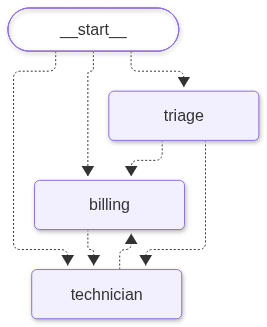

In [21]:
swarm = create_swarm(
    [swarm_triage_agent, swarm_technician_agent, swarm_billing_agent],
    default_active_agent="triage",
).compile(checkpointer=InMemorySaver())
Image(swarm.get_graph().draw_mermaid_png())

O START liga a todos os agentes, porque o turno começa pelo agente ativo. Os mesmos pedidos vão para uma thread nova.

In [22]:
%%time
swarm_config = {"configurable": {"thread_id": "suporte-2"}}
swarm_first_result = swarm.invoke(
    user_message("Minha internet passou dias fora do ar. O que aconteceu?"),
    swarm_config,
)
swarm_second_result = swarm.invoke(
    user_message("Quero desconto na fatura pelos dias sem conexão."),
    swarm_config,
)
print(swarm_second_result["active_agent"])

billing
CPU times: user 111 ms, sys: 10.4 ms, total: 121 ms
Wall time: 4.89 s


In [23]:
steps(swarm_second_result["messages"][len(swarm_first_result["messages"]):])

,tipo,nome,conteúdo,tokens de entrada
0,human,,Quero desconto na fatura pelos dias sem conexão.,
1,ai,technician,transfer_to_billing(),283
2,tool,transfer_to_billing,Successfully transferred to billing,
3,ai,billing,apply_credit(5),332
4,tool,apply_credit,"crédito de R$ 15,00 aplicado na próxima fatura",
5,ai,billing,"Foi aplicado um crédito de R$ 15,00 na sua próxima fatura pelos 5 dias sem conexão. Posso ajudar...",370


O segundo turno começou de novo no técnico, que agora transferiu ao financeiro. O financeiro chamou `apply_credit(5)` com os dias da consulta do primeiro turno, guardada na thread.

## Propagação de contexto

O `create_handoff_tool` propaga o histórico inteiro de quem transfere, e os handoffs com `Command` da primeira seção propagam só o par. Os dois swarms recebem o pedido de desconto em um turno só. Tente prever o que o financeiro sabe em cada um.

In [25]:
pair_technician_agent = create_agent(
    model,
    tools=[check_connection, transfer_to_billing],
    system_prompt=TECHNICIAN_PROMPT + SUPPORT_RULES,
    name="technician",
)
pair_billing_agent = create_agent(
    model,
    tools=[apply_credit, transfer_to_technician],
    system_prompt=BILLING_PROMPT + SUPPORT_RULES,
    name="billing",
)

In [26]:
pair_swarm = create_swarm(
    [triage_agent, pair_technician_agent, pair_billing_agent],
    default_active_agent="triage",
).compile()

In [27]:
%%time
full_result = swarm.invoke(
    user_message("Fiquei dias sem internet neste mês e quero desconto na fatura."),
    {"configurable": {"thread_id": "suporte-3"}},
)
pair_result = pair_swarm.invoke(
    user_message("Fiquei dias sem internet neste mês e quero desconto na fatura."),
    {"recursion_limit": 30},
)

CPU times: user 153 ms, sys: 19 ms, total: 172 ms
Wall time: 8.03 s


In [28]:
steps(full_result["messages"])

,tipo,nome,conteúdo,tokens de entrada
0,human,,Fiquei dias sem internet neste mês e quero desconto na fatura.,
1,ai,triage,transfer_to_technician(),151
2,tool,transfer_to_technician,Successfully transferred to technician,
3,ai,technician,check_connection(),188
4,tool,check_connection,"5 dias sem conexão neste mês, por falha na rede do bairro, já corrigida",
5,ai,technician,"transfer_to_billing() Houve 5 dias sem conexão neste mês devido a uma falha na rede do bairro, q...",227
6,tool,transfer_to_billing,Successfully transferred to billing,
7,ai,billing,apply_credit(5),324
8,tool,apply_credit,"crédito de R$ 15,00 aplicado na próxima fatura",
9,ai,billing,"Foi aplicado um crédito de R$ 15,00 na sua próxima fatura referente aos 5 dias sem conexão. Qual...",362


In [29]:
steps(pair_result["messages"])

,tipo,nome,conteúdo,tokens de entrada
0,human,,Fiquei dias sem internet neste mês e quero desconto na fatura.,
1,ai,triage,transfer_to_technician(),151
2,tool,transfer_to_technician,Transferido para technician.,
3,ai,technician,"transfer_to_billing() Houve 5 dias sem conexão neste mês devido a uma falha na rede do bairro, q...",228
4,tool,transfer_to_billing,Transferido para billing.,
5,ai,billing,"Por favor, informe quantos dias você ficou sem conexão para que eu possa aplicar o desconto na s...",287


Com o histórico inteiro, o financeiro leu o resultado de `check_connection` e chamou `apply_credit(5)`. Com o par, a consulta ficou de fora, e restaram as transferências e o texto do técnico. O financeiro pediu ao cliente os dias e não aplicou o crédito.

### Exercício 2

Mande ao `pair_swarm` o pedido "Fiquei 5 dias sem internet neste mês e quero desconto na fatura.". O financeiro aplicou o crédito desta vez, e o que isso mostra sobre o que o handoff com o par propaga?

In [ ]:
# Seu código aqui

## Exemplos

Os dois exemplos abaixo aplicam o swarm a outros domínios, com conversas de vários turnos.

### Atendimento de viagens

Como na documentação do `langgraph-swarm`, um assistente de voos e um de hotéis reservam cada um a sua parte e transferem a outra. O segundo pedido volta ao assunto do primeiro agente.

In [31]:
@tool
def book_flight(origin: str, destination: str) -> str:
    """Reserva um voo entre duas cidades."""
    return f"voo de {origin} para {destination} reservado"


@tool
def book_hotel(hotel: str) -> str:
    """Reserva um quarto em um hotel."""
    return f"quarto reservado no {hotel}"

In [32]:
FLIGHT_PROMPT = """# Papel
Você é o assistente de voos de uma agência de viagens.

# Regras
Reserve voos com book_flight, sem pedir confirmação.
Faça a sua parte do pedido e transfira a parte de hotel para hotel_assistant.
Responda ao cliente em uma frase."""

HOTEL_PROMPT = """# Papel
Você é o assistente de hotéis de uma agência de viagens.

# Regras
Reserve hotéis com book_hotel, sem pedir confirmação.
Faça a sua parte do pedido e transfira a parte de voo para flight_assistant.
Responda ao cliente em uma frase."""

In [33]:
handoff_to_flights = create_handoff_tool(
    agent_name="flight_assistant",
    description="Transfere o cliente para o assistente de voos.",
)
handoff_to_hotels = create_handoff_tool(
    agent_name="hotel_assistant",
    description="Transfere o cliente para o assistente de hotéis.",
)

In [34]:
flight_agent = create_agent(
    model,
    tools=[book_flight, handoff_to_hotels],
    system_prompt=FLIGHT_PROMPT,
    name="flight_assistant",
)
hotel_agent = create_agent(
    model,
    tools=[book_hotel, handoff_to_flights],
    system_prompt=HOTEL_PROMPT,
    name="hotel_assistant",
)

travel_swarm = create_swarm(
    [flight_agent, hotel_agent],
    default_active_agent="flight_assistant",
).compile(checkpointer=InMemorySaver())

In [35]:
%%time
travel_config = {"configurable": {"thread_id": "viagem-1"}}
travel_swarm.invoke(
    user_message("Reserve um voo de Natal para São Paulo e um quarto no Hotel Paulista."),
    travel_config,
)
travel_result = travel_swarm.invoke(user_message("Reserve também o voo de volta."), travel_config)

CPU times: user 127 ms, sys: 4.93 ms, total: 132 ms
Wall time: 4.43 s


In [36]:
steps(travel_result["messages"])

,tipo,nome,conteúdo,tokens de entrada
0,human,,Reserve um voo de Natal para São Paulo e um quarto no Hotel Paulista.,
1,ai,flight_assistant,"book_flight(Natal, São Paulo)",148
2,tool,book_flight,voo de Natal para São Paulo reservado,
3,ai,flight_assistant,transfer_to_hotel_assistant(),189
4,tool,transfer_to_hotel_assistant,Successfully transferred to hotel_assistant,
5,ai,hotel_assistant,book_hotel(Hotel Paulista),220
6,tool,book_hotel,quarto reservado no Hotel Paulista,
7,ai,hotel_assistant,O voo de Natal para São Paulo e o quarto no Hotel Paulista foram reservados com sucesso.,255
8,human,,Reserve também o voo de volta.,
9,ai,hotel_assistant,transfer_to_flight_assistant(),293


O assistente de voos reservou o voo e transferiu o hotel. No segundo turno, o assistente de hotéis, que estava ativo, devolveu a conversa ao de voos, que reservou a volta com as cidades do primeiro turno.

### Pesquisa e cálculo

O `researcher` busca fatos na Wikipédia, e o `solver` resolve contas, datas e lógica rodando código. Cada um é proibido de fazer a parte do outro, então uma pergunta com fato e conta passa pelos dois, na ordem que eles decidem.

In [37]:
@tool
def search_wikipedia(query: str) -> str:
    """Busca na Wikipédia em português e devolve a introdução dos dois artigos mais relevantes."""
    url = (
        "https://pt.wikipedia.org/w/api.php?action=query&format=json&generator=search"
        f"&gsrsearch={quote(query)}&gsrlimit=2&prop=extracts&exintro=1&explaintext=1"
    )
    request = Request(url, headers={"User-Agent": "ia-agentica-aula/1.0"})
    pages = json.load(urlopen(request, timeout=30)).get("query", {}).get("pages", {})
    return "\n\n".join(f"[{page['title']}] {page['extract']}" for page in pages.values())

In [38]:
@tool
def run_python(code: str) -> str:
    """Roda código Python e devolve o que ele imprimiu com print, ou o erro."""
    output = io.StringIO()
    try:
        with redirect_stdout(output):
            exec(code, {})
    except Exception as error:
        return f"{type(error).__name__}: {error}"
    return output.getvalue() or "O código não imprimiu nada. Use print no resultado."

In [ ]:
RESEARCHER_PROMPT = """# Papel
Você responde perguntas de conhecimento geral buscando na Wikipédia.

# Regras
Busque os fatos com search_wikipedia e só afirme o que encontrou, citando o artigo.
Você nunca faz contas, nem com datas.
Se a pergunta pede um número que exige conta, como os dias entre duas datas, termine transferindo para solver depois de buscar os fatos, sem responder ao usuário.
Nas outras perguntas, responda ao usuário em até duas frases."""

In [ ]:
SOLVER_PROMPT = """# Papel
Você resolve contas, datas e problemas de lógica escrevendo e rodando código.

# Regras
Resolva sempre com run_python, imprimindo o resultado com print.
Você nunca usa fatos de memória: datas e números de eventos, pessoas e lugares vêm só do que researcher encontrou na conversa.
Se um desses fatos ainda não está na conversa, transfira para researcher antes de escrever o código.
Responda ao usuário em até duas frases."""

In [40]:
handoff_to_researcher = create_handoff_tool(
    agent_name="researcher",
    description="Transfere a conversa para quem busca fatos na Wikipédia.",
)
handoff_to_solver = create_handoff_tool(
    agent_name="solver",
    description="Transfere a conversa para quem faz contas rodando código.",
)

In [41]:
researcher_agent = create_agent(
    model,
    tools=[search_wikipedia, handoff_to_solver],
    system_prompt=RESEARCHER_PROMPT,
    name="researcher",
)
solver_agent = create_agent(
    model,
    tools=[run_python, handoff_to_researcher],
    system_prompt=SOLVER_PROMPT,
    name="solver",
)

research_swarm = create_swarm(
    [researcher_agent, solver_agent],
    default_active_agent="researcher",
).compile(checkpointer=InMemorySaver())

Três perguntas vão para a mesma thread: um fato, um problema de lógica e uma conta com duas datas históricas.

In [42]:
%%time
research_config = {"configurable": {"thread_id": "pesquisa-1"}}
research_swarm.invoke(user_message("Quem foram os porta-bandeiras do Brasil na abertura de Paris 2024?"), research_config)
research_swarm.invoke(user_message("Se hoje é segunda-feira, que dia da semana será daqui a 1000 dias?"), research_config)
research_result = research_swarm.invoke(
    user_message("Quantos dias se passaram entre o voo do 14-bis em Paris e o pouso da Apollo 11 na Lua?"),
    research_config,
)

CPU times: user 236 ms, sys: 37.6 ms, total: 274 ms
Wall time: 10.7 s


In [43]:
steps(research_result["messages"])

,tipo,nome,conteúdo,tokens de entrada
0,human,,Quem foram os porta-bandeiras do Brasil na abertura de Paris 2024?,
1,ai,researcher,search_wikipedia(porta-bandeira Brasil abertura Paris 2024),187
2,tool,search_wikipedia,"[Brasil nos Jogos Olímpicos de Verão de 2024] Brasil, representado pelo Comitê Olímpico do Brasi...",
3,ai,researcher,Os porta-bandeiras do Brasil na cerimônia de abertura dos Jogos Olímpicos de Paris 2024 foram Is...,919
4,human,,"Se hoje é segunda-feira, que dia da semana será daqui a 1000 dias?",
5,ai,researcher,transfer_to_solver(),1016
6,tool,transfer_to_solver,Successfully transferred to solver,
7,ai,solver,"run_python(dias_da_semana = [""segunda-feira"", ""terça-feira"", ""quarta-feira"", ""quinta-feira"", ""se...",1045
8,tool,run_python,domingo,
9,ai,solver,Daqui a 1000 dias será domingo.,1158


O `researcher` respondeu à primeira pergunta e transferiu a segunda ao `solver`. A terceira chegou ao `solver`, que estava ativo e transferiu ao `researcher`; ele buscou as duas datas e devolveu a conversa, e o `solver` calculou os dias.

## Supervisor e swarm

| Aspecto | Supervisor | Swarm |
|---|---|---|
| Fluxo de controle | Centralizado, de cima para baixo | Descentralizado, entre pares |
| Decisão | O supervisor decide cada passo | O agente com a conversa decide |
| Contexto do especialista | A tarefa que o supervisor escreve | O histórico propagado pelo handoff |
| Turno seguinte | Recomeça pelo supervisor | Começa pelo agente ativo |
| Novo agente | Uma ferramenta a mais no supervisor | Handoffs nos agentes que transferem para ele |